# Gateway tracking: perfect versus LSO-estimated observer orbit

**This is the main notebook.** It answers one question over one halo-observer nominal period: **how much does imperfect knowledge of the observer change the estimated Lunar Gateway position and velocity?**

The same true spacecraft trajectories and the same noisy Gateway observations are used in both cases. Perfect knowledge means that the observer state is known exactly; it does **not** mean the Gateway state or camera measurements are perfect.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "configs/baseline.json").exists() and (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from within the project checkout")
sys.path.insert(0, str(ROOT / "src"))
from halo_tracking.study import load_config
cfg = load_config(ROOT / "configs/baseline.json")
cfg["simulation"]["periods"] = 1.0


## 1. Matched comparison

| Assumption | Perfect observer | LSO-estimated observer |
|---|---|---|
| Observer state supplied to Gateway estimator | Exact true state | State estimated from LSO angles |
| Initial observer uncertainty | Zero | 1 km and 0.01 m/s per axis, 1σ |
| Initial Gateway uncertainty | 1 km and 0.01 m/s per axis, 1σ | Same |
| Observer-to-Gateway camera | 1 arcsecond per angle | Same measurements and noise |
| LSO | Not needed | 30° N, 270° E; 1 arcsecond per angle |

These are the baseline settings; the configuration table below displays the values actually used. Both optical links use **angles only** in this focused comparison. The cadence is 30 minutes. Earth/Moon occultation is included for Gateway observations; the LSO uses the configured elevation mask. Optical brightness, Sun exclusions and camera attitude errors are not modeled.

The true observer remains on the supplied initial-value trajectory in both cases. The imperfect case introduces uncertainty in our **knowledge** of it, not a different physical orbit.

In [2]:
from IPython.display import HTML, Markdown, display
settings = [
    ("Duration", f"1 observer nominal period = {cfg['orbit']['period_tu'] * cfg['time_unit_s'] / 86400:.2f} days"),
    ("Observer initial position / velocity 1σ", f"{cfg['estimation']['initial_position_sigma_km']:g} km / {1000*cfg['estimation']['initial_velocity_sigma_km_s']:g} m/s per axis"),
    ("Gateway initial position / velocity 1σ", f"{cfg['comparison']['gateway_position_sigma_km']:g} km / {1000*cfg['comparison']['gateway_velocity_sigma_km_s']:g} m/s per axis"),
    ("LSO angular noise 1σ", f"{cfg['measurement']['angle_sigma_arcsec']:g} arcsec per angle"),
    ("Gateway camera angular noise 1σ", f"{cfg['comparison']['gateway_camera_sigma_arcsec']:g} arcsec per angle")]
display(HTML("<table>"+"".join(f"<tr><th>{name}</th><td>{value}</td></tr>" for name,value in settings)+"</table>"))

Duration,1 observer nominal period = 8.06 days
Observer initial position / velocity 1σ,1 km / 0.01 m/s per axis
Gateway initial position / velocity 1σ,1 km / 0.01 m/s per axis
LSO angular noise 1σ,1 arcsec per angle
Gateway camera angular noise 1σ,1 arcsec per angle


In [3]:
from halo_tracking.gateway_comparison import run_gateway_comparison, save_comparison
result = run_gateway_comparison(cfg)
report = save_comparison(result, ROOT / "results/gateway_comparison")

/workspace/scratch/678b6a3ef004/Halo_Orbit_Tracking/src/halo_tracking/gateway_comparison.py:106: UserWarning: Supplied rounded state does not close within 1 km. Treat as an initial-value trajectory, not a validated periodic halo.
  truth=make_truth(cfg);times=truth['times'];truth['config']=cfg


## 2. Geometry and what the LSO knows

The first figure is context: both true trajectories are identical across the two estimation cases. The dots mark their initial states. The axis scale is in thousands of kilometers, with equal physical scale on all three axes.

The second figure shows the observer's estimated-state error and its local covariance prediction. The shaded interval contains LSO observations. Outside that interval, the observer estimate and covariance propagate without LSO corrections. **RSS σ is a covariance summary, not a guaranteed bound on the error magnitude.**

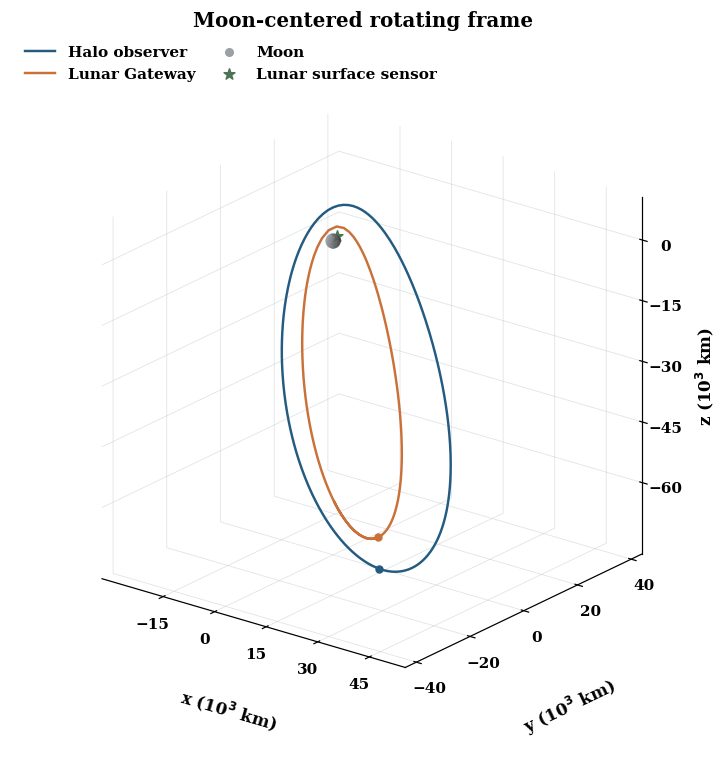

In [4]:
from halo_tracking.plotting import geometry, observer_knowledge, gateway_comparison_figures, export
fig_geometry = geometry(result)
export(fig_geometry, ROOT / "results/gateway_comparison/geometry.png")

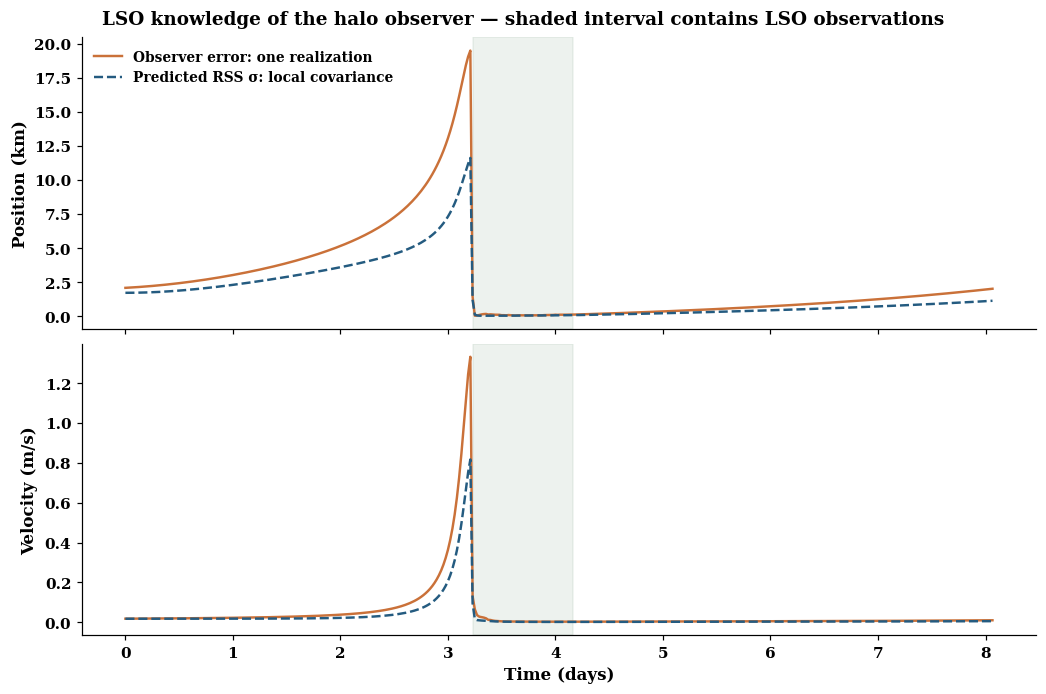

In [5]:
fig_observer = observer_knowledge(result)
export(fig_observer, ROOT / "results/gateway_comparison/observer.png")

## 3. What changes in Gateway tracking

**Actual-error plot:** distance between the estimated and true Gateway state in this one shared noise realization. Lower is better. It is an actual orbit estimate, not just a pointing-error projection.

**Predicted-uncertainty plot:** square root of the position/velocity covariance-block trace. Lower means the estimator predicts better knowledge. These are local linearized predictions; they can be optimistic if the approximation is inaccurate.

In the imperfect case, the estimator carries observer–Gateway cross-covariance through time. Gateway measurements do not refine the observer: its state knowledge comes from the LSO. LSO updates can also correct Gateway indirectly through the retained correlation.

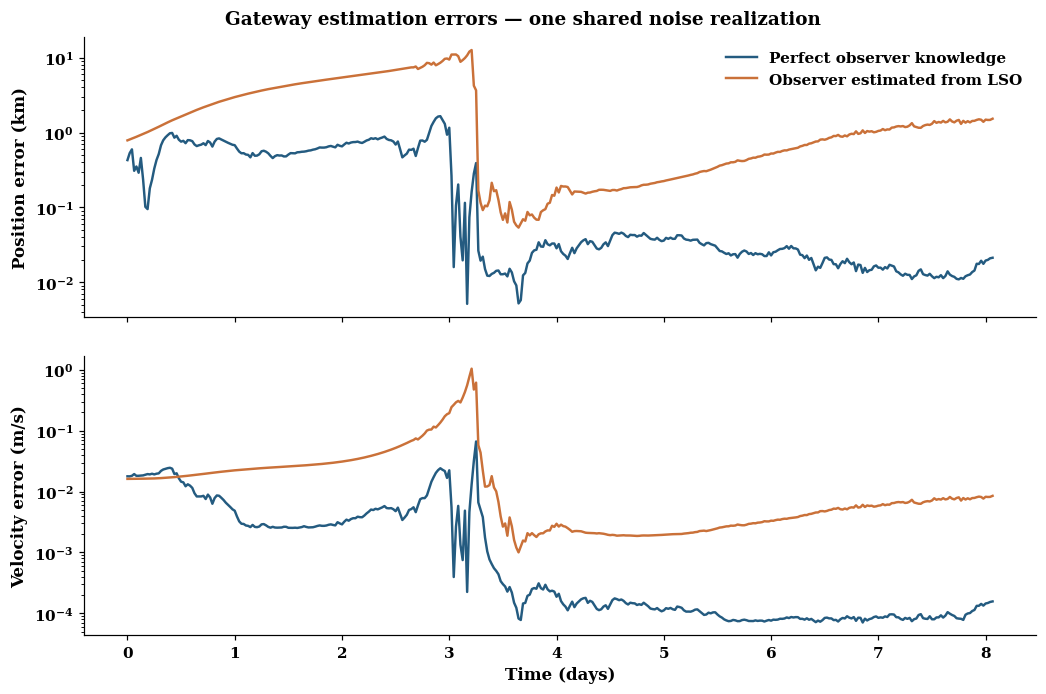

In [6]:
figures = gateway_comparison_figures(result)
# Display each figure in its own cell to avoid an overcrowded subplot grid.
fig_errors = figures["errors"]
export(fig_errors, ROOT / "results/gateway_comparison/errors.png")
import matplotlib.pyplot as plt
plt.close(figures["uncertainty"])

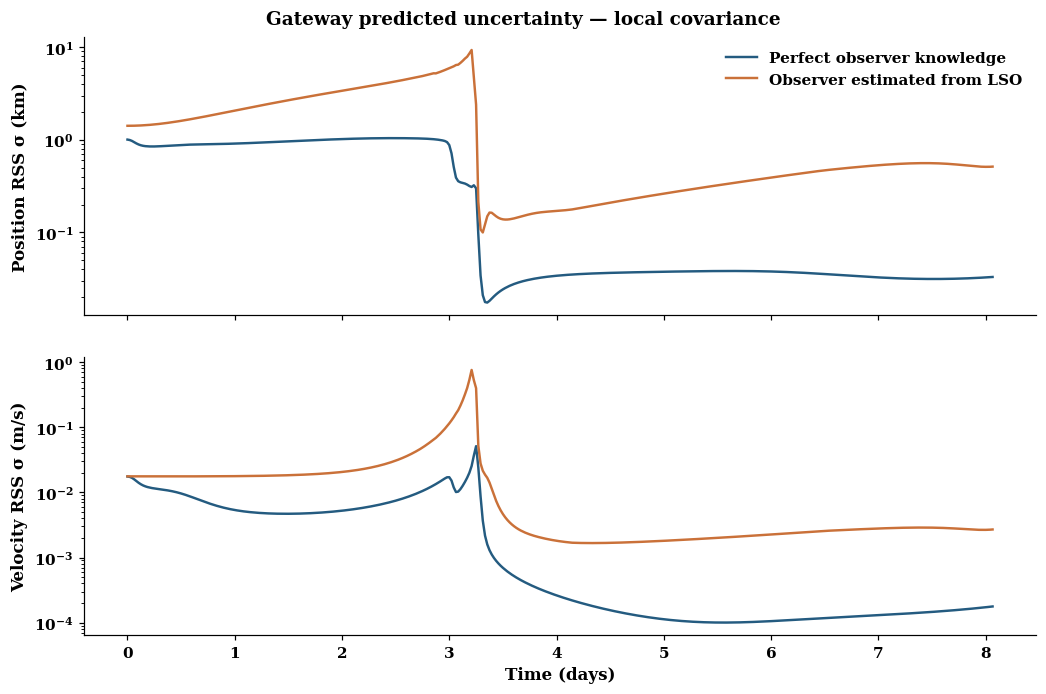

In [7]:
# Re-create the uncertainty figure for a separate notebook output.
figures_uncertainty = gateway_comparison_figures(result)
plt.close(figures_uncertainty["errors"])
fig_uncertainty = figures_uncertainty["uncertainty"]
export(fig_uncertainty, ROOT / "results/gateway_comparison/uncertainty.png")

## 4. Numerical conclusions

The table separates **actual errors from one realization** from **predicted uncertainty**. It should be read with the assumptions above, especially the Gateway prior and observing geometry.

In [8]:
rows=[]
for key,label in [("perfect","Perfect observer knowledge"),("lso_estimated","Observer estimated from LSO")]:
    item=report[key]
    values=[label, f"{1000*item['position_rmse_km']:.1f}",
            f"{1000*item['final_position_error_km']:.1f}",
            f"{1000*item['final_position_forecast_rss_sigma_km']:.1f}",
            f"{item['final_velocity_error_m_s']:.3g}"]
    rows.append("<tr>"+"".join("<td>"+v+"</td>" for v in values)+"</tr>")
headers=["Observer knowledge", "Gateway position RMSE over arc (m)", "Final actual position error (m)", "Final predicted position RSS σ (m)", "Final actual velocity error (m/s)"]
display(HTML("<table><tr>"+"".join("<th>"+v+"</th>" for v in headers)+"</tr>"+"".join(rows)+"</table>"))

Observer knowledge,Gateway position RMSE over arc (m),Final actual position error (m),Final predicted position RSS σ (m),Final actual velocity error (m/s)
Perfect observer knowledge,443.9,21.2,33.1,0.000157
Observer estimated from LSO,3525.7,1528.9,513.2,0.00852


In [9]:
import numpy as np
ideal=report["perfect"]; estimated=report["lso_estimated"]
ratio=estimated["final_position_forecast_rss_sigma_km"]/ideal["final_position_forecast_rss_sigma_km"]
available=np.flatnonzero(result["lso_available"])
start=result["times"][available[0]]*cfg["time_unit_s"]/86400 if len(available) else float("nan")
end=result["times"][available[-1]]*cfg["time_unit_s"]/86400 if len(available) else float("nan")
conclusions = f"""
- **Predicted Gateway uncertainty increases:** final position RSS σ is {1000*ideal['final_position_forecast_rss_sigma_km']:.1f} m with exact observer knowledge and {1000*estimated['final_position_forecast_rss_sigma_km']:.1f} m with LSO-estimated knowledge—**{ratio:.1f} times larger** in this scenario.
- **The paired actual estimates also differ:** final Gateway position error is {1000*ideal['final_position_error_km']:.1f} m versus {1000*estimated['final_position_error_km']:.1f} m. These are sample outcomes, not ensemble-average accuracy claims.
- **The LSO observing window matters:** its {int(result['lso_available'].sum())} available observations occur between days {start:.2f} and {end:.2f}. Knowledge of the observer degrades again after the LSO window, and that uncertainty propagates into Gateway tracking.
- **The experiment demonstrates the effect of observer knowledge.** The exact numerical degradation depends on the initial uncertainties, relative orbit phases, noise and observation schedule; the two cases have deliberately matched Gateway conditions.
"""
display(Markdown(conclusions))


- **Predicted Gateway uncertainty increases:** final position RSS σ is 33.1 m with exact observer knowledge and 513.2 m with LSO-estimated knowledge—**15.5 times larger** in this scenario.
- **The paired actual estimates also differ:** final Gateway position error is 21.2 m versus 1528.9 m. These are sample outcomes, not ensemble-average accuracy claims.
- **The LSO observing window matters:** its 45 available observations occur between days 3.23 and 4.15. Knowledge of the observer degrades again after the LSO window, and that uncertainty propagates into Gateway tracking.
- **The experiment demonstrates the effect of observer knowledge.** The exact numerical degradation depends on the initial uncertainties, relative orbit phases, noise and observation schedule; the two cases have deliberately matched Gateway conditions.


## Limits of the conclusion

This is one **8.06-day observer-period** study, not 5–20-period propagation. The supplied state is labeled `SNRHL2` (southern NRHO) and is rounded; the one-period closure check remains documented. No stationkeeping or unmodeled forces are introduced.

The earlier observer-filter validation showed covariance overconfidence near the first LSO update. This comparison retains that baseline rather than altering your uncertainties to obtain favorable statistics. Its predicted covariance therefore supports a **conditional comparison**, not yet a validated physical accuracy guarantee. Monte Carlo and alternative nonlinear filters are supporting checks in `notebooks/advanced/`, not prerequisites for understanding this notebook.